# EDA and Quality Checks

In [5]:
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == 'notebooks' else cwd
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import geopandas as gpd
from src.config import PROCESSED_DIR
import matplotlib.pyplot as plt
import seaborn as sns

## Load processed files

In [6]:
# Define file paths
ev_parquet_path = PROCESSED_DIR / "ev_stations.parquet"
gas_parquet_path = PROCESSED_DIR / "gas_stations.parquet"

# Load GeoParquet files
print("Loading GeoParquet files...")
ev_gdf = gpd.read_parquet(ev_parquet_path)
gas_gdf = gpd.read_parquet(gas_parquet_path)

Loading GeoParquet files...


## Schema Inspection

In [7]:
# Display data types
print("EV Data Types: ")
print(f"{ev_gdf.dtypes}")
print("Gas Data Types: ")
print(f"{gas_gdf.dtypes}")

# Check if required columns exist
required_ev_cols = [
    'station_id', 'station_name', 'latitude', 'longitude', 'access_code',
    'level1_ports', 'level2_ports', 'dcfc_ports', 'total_ev_ports', 'has_dcfc',
]
required_gas_cols = [
    'station_id', 'name', 'address', 'city', 'zip', 'source', 'source_snapshot_date', 'geometry',
]
missing_ev_cols = [col for col in required_ev_cols if col not in ev_gdf.columns]
missing_gas_cols = [col for col in required_gas_cols if col not in gas_gdf.columns]
assert not missing_ev_cols, f"Missing {missing_ev_cols}"
assert not missing_gas_cols, f"Missing {missing_gas_cols}"

# Confirm if geometry colummns are active
print("EV geometry column:", ev_gdf.geometry.name)
print("Gas geometry column:", gas_gdf.geometry.name)

print("EV geometry dtype:", ev_gdf.geometry.dtype)
print("Gas geometry dtype:", gas_gdf.geometry.dtype)

print("EV null geometries:", ev_gdf.geometry.isna().sum())
print("Gas null geometries:", gas_gdf.geometry.isna().sum())

EV Data Types: 
id                         int64
station_name              object
street_address            object
city                      object
state                     object
zip                        int64
latitude                 float64
longitude                float64
status_code               object
access_code               object
ev_connector_types        object
ev_dc_fast_num           float64
ev_level1_evse_num       float64
ev_level2_evse_num       float64
ev_network                object
ev_pricing                object
facility_type             object
funding_sources           object
date_last_confirmed       object
open_date                 object
owner_type_code           object
dcfc_ports                 int64
level1_ports               int64
level2_ports               int64
total_ev_ports             int64
has_dcfc                    bool
source                    object
source_snapshot_date      object
geometry                geometry
dtype: object
Gas Data Type

## EV Inspection

ev_network
ChargePoint Network    14131
Tesla Destination        786
Non-Networked            769
Tesla                    644
Blink Network            620
                       ...  
XEAL                       1
CHARGEUP                   1
FLITWAY                    1
EVOKE                      1
POWERPORT_EVC              1
Name: count, Length: 64, dtype: int64
status_code
E    19798
T      395
P       61
Name: count, dtype: int64


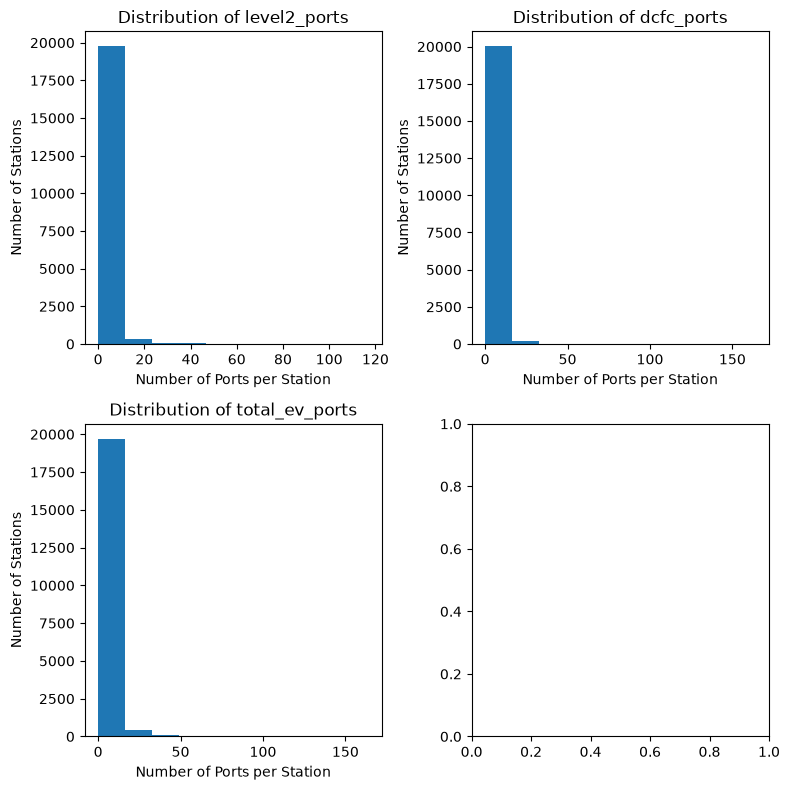

In [19]:
# Network Counts
network_counts = ev_gdf['ev_network'].value_counts(dropna=False)
print(network_counts)

# Status Count
status_counts = ev_gdf['status_code'].value_counts(dropna=False)
print(status_counts)

# Summarize Port Counts
port_cols = ['level2_ports', 'dcfc_ports', 'total_ev_ports']
ev_gdf[port_cols].describe()

# Histogram for Port Counts
fig, axes = plt.subplots(2,2, figsize=(8,8))
axes = axes.flatten()
for i,col in enumerate(port_cols):
    axes[i].hist(ev_gdf[col])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Number of Ports per Station')
    axes[i].set_ylabel("Number of Stations")
plt.tight_layout()
plt.show()




## Gas Inspection

In [13]:
# Count records by city, ZIP
city_counts = gas_gdf['city'].value_counts(dropna=False)
zip_counts = gas_gdf['zip'].value_counts(dropna=False)
print(city_counts.head(20))
print("\n")
print(zip_counts.head(20))

# Recompute n_raw by reading the latest raw snapshot directly
from src.transform.clean_stations import find_latest_files
_, gas_raw_path = find_latest_files()
gas_raw = gpd.read_file(gas_raw_path)

n_raw = len(gas_raw)
n_clean = len(gas_gdf)
n_removed = n_raw - n_clean

print(f"Raw gas stations:      {n_raw}")
print(f"After dedup/cleaning:  {n_clean}")
print(f"Removed:               {n_removed} ({n_removed / n_raw:.1%})")

# Rows with missing names or addresses
missing_names_addresses = gas_gdf[gas_gdf['name'].isna() | gas_gdf['address'].isna()]
print(missing_names_addresses.head(10))

city
LOS ANGELES       361
SAN DIEGO         258
SACRAMENTO        197
SAN JOSE          192
FRESNO            182
BAKERSFIELD       181
STOCKTON          102
SAN FRANCISCO      90
LONG BEACH         87
MODESTO            86
OAKLAND            85
RIVERSIDE          82
ANAHEIM            71
REDDING            67
ONTARIO            58
SANTA ROSA         56
SALINAS            55
SAN BERNARDINO     55
VISALIA            54
FONTANA            50
Name: count, dtype: int64


zip
93274    39
93257    38
92335    33
93308    31
92345    30
93637    29
93722    28
93307    27
93446    27
93230    26
92021    25
95380    25
92154    25
93901    25
96003    24
94533    24
95678    24
91761    24
93304    23
94080    23
Name: count, dtype: int64
Latest EV CSV:      C:\Users\caden\Documents\CA EV Analytics\data\raw\afdc_ev_stations_2026-07-12.csv
Latest Gas GeoJSON: C:\Users\caden\Documents\CA EV Analytics\data\raw\cec_gas_stations_2026-07-12.geojson
Raw gas stations:      9617
After dedup/cleaning:

## Spatial Checks

In [14]:
# Reproject both layers to EPSG:4326 for plotting
ev_web = ev_gdf.to_crs("EPSG:4326")
gas_web = gas_gdf.to_crs("EPSG:4326")

print(f"EV CRS after projection: {ev_web}")
print(f"Gas CRS after projection {gas_web}")

EV CRS after projection:            id                            station_name  \
0        1523           Los Angeles Convention Center   
1        6355                  Scripps Green Hospital   
2        6405                           Galpin Motors   
3        6425                       Galleria at Tyler   
4        6505  City of Pasadena - Holly Street Garage   
...       ...                                     ...   
20249  463581                            DGS DAWG - 7   
20250  463582                            DGS DAWG - 8   
20251  463583                            DGS DAWG - 9   
20252  463592                    JD COLLINS CHARGER 2   
20253  463603                     Pre's Test Location   

                street_address         city state    zip   latitude  \
0           1201 S Figueroa St  Los Angeles    CA  90015  34.040539   
1      10666 N Torrey Pines Rd     La Jolla    CA  92037  32.899470   
2            15421 Roscoe Blvd    Sepulveda    CA  91343  34.221665   
3     

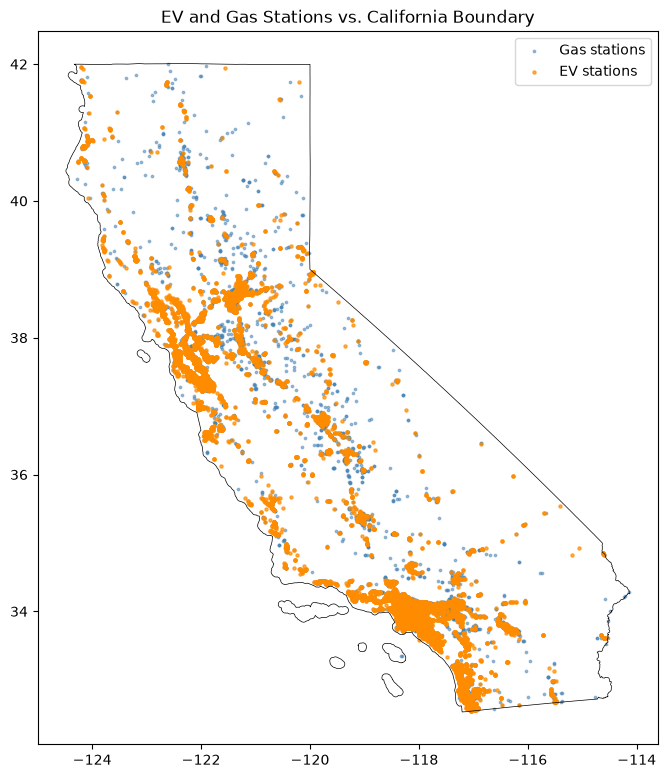

In [15]:
# Plot points over California boundary
import geopandas as gpd
from src.config import EXTERNAL_DIR

tracts = gpd.read_file(EXTERNAL_DIR / "california_tracts") 
ca_boundary = tracts.to_crs("EPSG:4326").dissolve()  

fig, ax = plt.subplots(figsize=(8, 10))
ca_boundary.boundary.plot(ax=ax, color='black', linewidth=0.5)
gas_web.plot(ax=ax, markersize=3, color='steelblue', alpha=0.5, label='Gas stations')
ev_web.plot(ax=ax, markersize=5, color='darkorange', alpha=0.7, label='EV stations')
ax.set_title("EV and Gas Stations vs. California Boundary")
ax.legend()
plt.show()

In [16]:
# Numeric check: any points clearly outside CA bounding box after cleaning?
ev_outliers = ev_web[~ev_web.geometry.x.between(-125, -113) | ~ev_web.geometry.y.between(32.5, 43.0)]
gas_outliers = gas_web[~gas_web.geometry.x.between(-125, -113) | ~gas_web.geometry.y.between(32.5, 43.0)]

print(f"EV points outside CA bbox: {len(ev_outliers)}")
print(f"Gas points outside CA bbox: {len(gas_outliers)}")

EV points outside CA bbox: 0
Gas points outside CA bbox: 0
